# 02 · Choosing K fairly: distance, scaling and cross-validation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/KNN_IRIS_classification/blob/main/notebooks/02_distance_k_and_cross_validation.ipynb)

**After this notebook you will be able to** pick the number of neighbours `k` with 5-fold cross-validation, explain why feature scales matter for distances, and say honestly how much a small test set can tell you.

| | |
|---|---|
| Who it is for | Anyone who finished notebook `01`. |
| Time | About 40 minutes to read; the code runs in a few seconds on a CPU. |
| Random seed | `42` everywhere. |
| Next | `03` compares KNN with other models; `04` explains KNN's decisions. |

## 1. The big question

In notebook 01 we used `k=1` because my first script did. Was that a good choice? Three questions follow:

1. **How many neighbours** should vote?
2. **What does "close" mean** when measurements have different units?
3. **How can we measure quality** without fooling ourselves with one lucky (or unlucky) split?

## 2. Intuition first

**Choosing k.** Imagine guessing a student's favourite sport by asking neighbours.

- Ask **only one** person (`k=1`): you copy that person, even if they are an odd one out. Your guess is *jumpy*.
- Ask **the whole school** (`k` huge): everyone gets the answer of the biggest group. Your guess is *blurry* and ignores who is actually near you.
- Somewhere in between is a good balance.

**Cross-validation.** Imagine a teacher with 120 practice questions. Instead of one quiz, she splits the questions into **5 piles**. She runs 5 rounds: in each round 4 piles are for studying and 1 pile is the quiz. Every question is a quiz question exactly once, and the final grade is the **average of 5 quizzes**. That is 5-fold cross-validation.

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/KNN_IRIS_classification.git"], check=True)
    os.chdir("KNN_IRIS_classification/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.iris_knn import (SEED, FEATURES, CLASSES, load_iris_frame, split_data,
                          scatter_species, plot_decision_regions, save_figure)

np.random.seed(SEED)               # fixed seed: you will get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, cross_val_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = load_iris_frame()
x_train, x_test, y_train, y_test = split_data(df, test_size=0.2, seed=SEED)
print("train:", x_train.shape, " test:", x_test.shape)

train: (120, 4)  test: (30, 4)


We split once, exactly like in notebook 01. **From now on the test set is locked in a drawer.** All choices (which `k`, which distance) are made on the 120 training flowers only. We open the drawer once, at the end.

## 3. A picture: what does k do to the decision boundary?

To draw a map we must use only two features (petal length and width). The colours show which species a new flower at that spot would get. **Predict first:** which of the three panels (k = 1, 10, 100) has the most jagged, wiggly boundary?

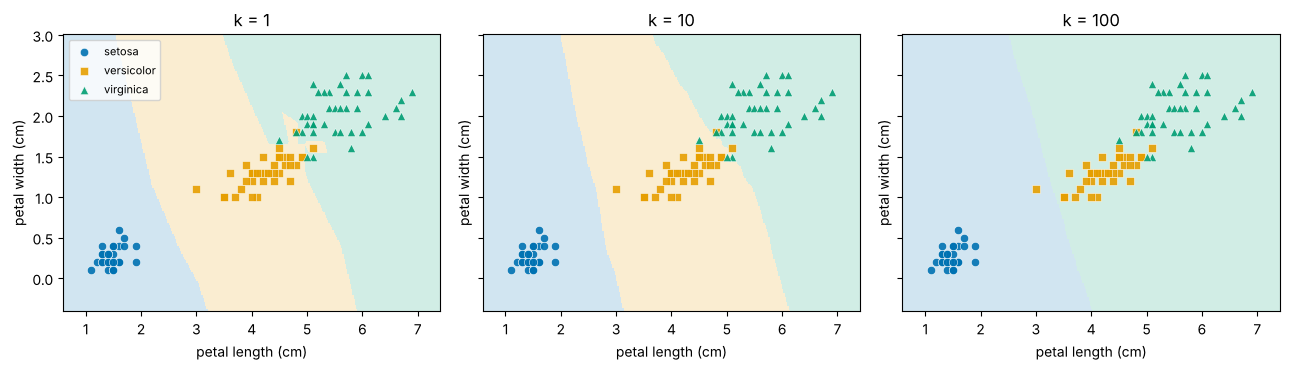

In [3]:
train_df = x_train.assign(species=y_train)
fx, fy = "petal length (cm)", "petal width (cm)"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, k in zip(axes, [1, 10, 100]):
    two_feature_model = KNeighborsClassifier(n_neighbors=k).fit(train_df[[fx, fy]], train_df["species"])
    plot_decision_regions(ax, two_feature_model, train_df, fx, fy, title=f"k = {k}")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, "02_decision_regions.png")
plt.show()

*Figure 1. What to notice:* with `k=1` the boundary bends around single flowers (small islands of colour near the overlap of *versicolor* and *virginica*). With `k=10` it is smooth and still follows the three groups. With `k=100` (more than the 40 flowers each species has in the training set) the *versicolor* region has completely disappeared: every spot on the map is claimed by the two other species.

In machine-learning words: tiny `k` **overfits** (it memorises noise), huge `k` **underfits** (it misses real structure).

## 4. A little math

**Distance family.** For two flowers $a$ and $b$ with $n$ measurements:

$$d_p(a,b) = \left(\sum_{i=1}^{n} |a_i - b_i|^p\right)^{1/p}$$

- $p=2$ is the **Euclidean** distance from notebook 01 (the straight line).
- $p=1$ is the **Manhattan** distance (walk along a street grid: add up the absolute differences).

**Standardising.** To put every feature on the same scale we replace each value $x$ by

$$z = \frac{x - \mu}{\sigma}$$

where $\mu$ is the feature's mean and $\sigma$ its standard deviation, both computed **on the training data only**. After this, every feature has mean 0 and spread 1.

## 5. Does the scale of a feature matter?

We want a fair way to compare options, so first let us build it: 5-fold cross-validation repeated 10 times with different shuffles, on the training set. This gives 50 quiz grades per option, which is more stable than 5.

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

def cv_scores(model, X):
    """50 quiz grades (5 folds x 10 repeats) on the training data."""
    return cross_val_score(model, X, y_train, cv=cv, scoring="accuracy")

scores_k1 = cv_scores(KNeighborsClassifier(n_neighbors=1), x_train)
print("number of quiz grades:", len(scores_k1))
print("first five grades    :", np.round(scores_k1[:5], 3))
print(f"k=1 mean accuracy    : {scores_k1.mean():.3f}  (spread {scores_k1.std():.3f})")

number of quiz grades: 50
first five grades    : [0.917 1.    0.958 0.958 0.958]
k=1 mean accuracy    : 0.950  (spread 0.039)


Each grade is the accuracy on one quiz pile of 24 flowers. The *mean* is our estimate; the *spread* (standard deviation) tells us how much a single grade jumps around. (This `k=1` model uses the raw measurements; the standardised `k=1` model of section 6 scores a little differently, as section 5 will explain.)

Here is how the 5 folds of one round look: each of the 120 training flowers is in the quiz pile exactly once.

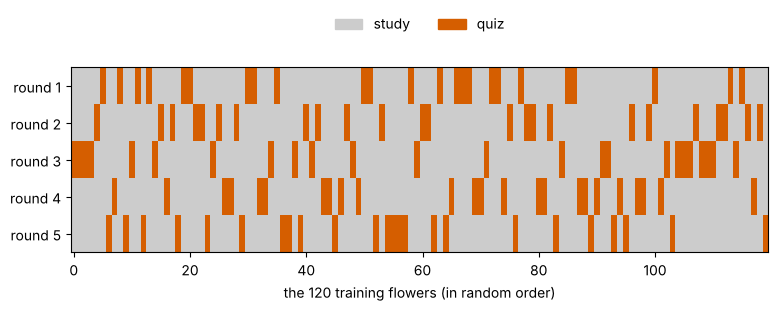

In [5]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
roles = np.zeros((5, len(x_train)))
for round_number, (study, quiz) in enumerate(skf.split(x_train, y_train)):
    roles[round_number, quiz] = 1

fig, ax = plt.subplots(figsize=(9, 2.4))
ax.imshow(roles, aspect="auto", cmap=ListedColormap(["#CCCCCC", "#D55E00"]), interpolation="nearest")
ax.set_yticks(range(5))
ax.set_yticklabels([f"round {i + 1}" for i in range(5)])
ax.set_xlabel("the 120 training flowers (in random order)")
ax.legend(handles=[Patch(color="#CCCCCC", label="study"), Patch(color="#D55E00", label="quiz")],
          loc="upper center", bbox_to_anchor=(0.5, 1.35), ncol=2, frameon=False)
save_figure(fig, "02_cross_validation_folds.png")
plt.show()

*Figure 2. What to notice:* in every column exactly one round is orange. Every flower is used as a quiz question once and as study material four times.

Now the question. Does standardising help, and does Manhattan beat Euclidean? We compare four settings with `k=5`. **Predict first:** which do you expect to win?

(For a fair test, the scaler lives *inside* a pipeline, so in each round it learns its mean and spread from the study part only.)

In [6]:
def make_model(k, metric="euclidean", scale=True):
    knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
    return make_pipeline(StandardScaler(), knn) if scale else knn

rows = []
for scale in [False, True]:
    for metric in ["euclidean", "manhattan"]:
        s = cv_scores(make_model(5, metric, scale), x_train)
        rows.append({"standardised": scale, "distance": metric,
                     "mean accuracy": round(s.mean(), 3), "spread": round(s.std(), 3)})
pd.DataFrame(rows)

,standardised,distance,mean accuracy,spread
0,False,euclidean,0.965,0.036
1,False,manhattan,0.961,0.035
2,True,euclidean,0.954,0.038
3,True,manhattan,0.952,0.039


All four settings are within 1.3 percentage points of each other, much less than the spread (about 0.04). **On the Iris data they are indistinguishable.** That is not surprising: all four measurements are in centimetres and have similar ranges.

So is scaling pointless? Not in general. Let us break the data on purpose. Suppose an engineer stored the sepal width in *hundredths* of a centimetre (so `3.0` becomes `300`). Nothing about the flowers changed, only the units.

In [7]:
x_units = x_train.copy()
x_units["sepal width (cm)"] = x_units["sepal width (cm)"] * 100

for scale in [False, True]:
    s = cv_scores(make_model(5, "euclidean", scale), x_units)
    print(f"standardised={scale!s:5}  mean accuracy = {s.mean():.3f}")

standardised=False  mean accuracy = 0.745


standardised=True   mean accuracy = 0.954


Without standardising, accuracy collapses (0.745 against 0.954). The huge numbers of one feature dominate every distance, so the other three features are practically ignored. With standardising, the units no longer matter and we get the same 0.954 as before.

**Rule of thumb:** distance-based models need features on comparable scales. We will keep the scaler in our pipeline: on Iris it costs nothing, and it protects us when units differ.

## 6. Choosing k with cross-validation

We try every `k` from 1 to 30 and compute the 50 quiz grades for each. Before looking at the numbers we fix the rule: **choose the `k` with the highest mean accuracy; if several tie, choose the largest of them** (a larger `k` gives a smoother, less jumpy model).

In [8]:
results = []
for k in range(1, 31):
    s = cv_scores(make_model(k), x_train)
    results.append({"k": k, "mean": s.mean(), "std": s.std()})
results = pd.DataFrame(results)

best_mean = results["mean"].max()
tied = results[np.isclose(results["mean"], best_mean)]
best_k = int(tied["k"].max())
print("best mean accuracy:", round(best_mean, 4))
print("k values that reach it:", tied["k"].tolist())
print("chosen k:", best_k)
results.round(4).head(8)

best mean accuracy: 0.955
k values that reach it: [3]
chosen k: 3


,k,mean,std
0,1,0.9325,0.0448
1,2,0.9417,0.0433
2,3,0.9550,0.0407
3,4,0.9517,0.0420
4,5,0.9542,0.0384
5,6,0.9483,0.0387
6,7,0.9467,0.0417
7,8,0.9500,0.0425


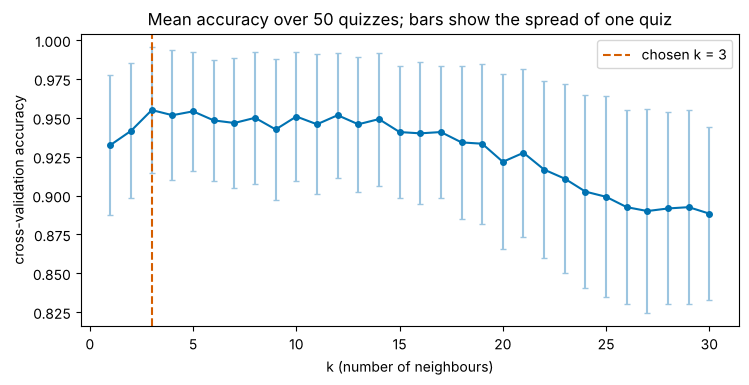

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.errorbar(results["k"], results["mean"], yerr=results["std"], fmt="o-", color="#0072B2",
            ecolor="#9CC5E0", capsize=2, markersize=4)
ax.axvline(best_k, color="#D55E00", linestyle="--", label=f"chosen k = {best_k}")
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("cross-validation accuracy")
ax.set_title("Mean accuracy over 50 quizzes; bars show the spread of one quiz")
ax.legend()
save_figure(fig, "02_choosing_k.png")
plt.show()

*Figure 3. What to notice:*

- Accuracy is lower for the very largest `k`: the "ask the whole school" effect, and the spread grows too.
- For small `k` (roughly 3 to 14) the curve is flat. Differences of a few tenths of a percent are **smaller than the bars**, so we cannot claim that `k=3` is truly better than `k=5` or `k=10`.
- `k=1` is a little lower than its neighbours, in line with the jumpy boundary of Figure 1.

Cross-validation gave a sensible *region* of good values and a rule-based pick (`k=3`), not a magic single best number.

## 7. Open the drawer: one honest test

Now we train on all 120 training flowers and look at the test set **once**. We compare our chosen `k` with the original `k=1`.

In [10]:
final_rows = []
for name, k in [("k = 1 (original script)", 1), (f"k = {best_k} (chosen by CV)", best_k)]:
    cv_part = results.loc[results["k"] == k].iloc[0]
    model = make_model(k).fit(x_train, y_train)
    correct = int((model.predict(x_test) == y_test).sum())
    final_rows.append({"model": name,
                       "CV accuracy (train set)": f"{cv_part['mean']:.3f} +/- {cv_part['std']:.3f}",
                       "test flowers correct": f"{correct} / {len(y_test)}",
                       "test accuracy": round(correct / len(y_test), 3)})
pd.DataFrame(final_rows)

,model,CV accuracy (train set),test flowers correct,test accuracy
0,k = 1 (original script),0.932 +/- 0.045,29 / 30,0.967
1,k = 3 (chosen by CV),0.955 +/- 0.041,28 / 30,0.933


Read this table carefully and honestly. The CV estimate prefers `k=3`, yet on the 30 test flowers `k=3` gets **one flower fewer** right than `k=1`. Does that mean cross-validation was wrong?

No. One flower is 3.3 percentage points, which is *within* the normal wobble we measured (spread about 0.04). The test set is simply too small to separate two models that differ by about 2 points in CV. In cross-validation every one of the 120 training flowers is a quiz question ten times (once per repeat); the test set has only 30 flowers, each used once. **When two numbers differ by less than their spread, we should say "we cannot tell them apart" instead of declaring a winner.**

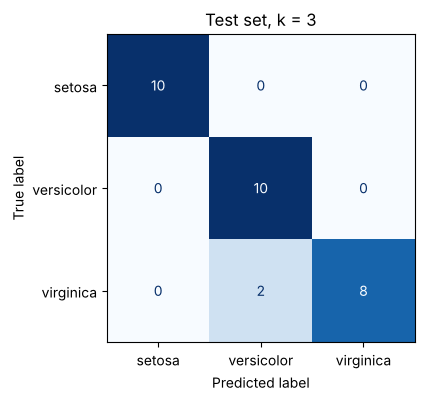

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

final_model = make_model(best_k).fit(x_train, y_train)
fig, ax = plt.subplots(figsize=(4.4, 4))
ConfusionMatrixDisplay.from_estimator(final_model, x_test, y_test, display_labels=CLASSES,
                                      cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Test set, k = {best_k}")
save_figure(fig, "02_confusion_matrix.png")
plt.show()

*Figure 4. What to notice:* rows are the true species and columns the predicted ones; correct answers are on the diagonal. Both mistakes are *virginica* flowers called *versicolor*, the two groups that overlap in notebook 01.

## 8. Check yourself

**Question 1.** Why do we repeat the 5-fold cross-validation 10 times with different shuffles?

<details>
<summary>Show the answer</summary>

One 5-fold run depends on how the flowers happened to be shuffled into piles. Repeating with new shuffles gives 50 grades instead of 5 and a more stable average. It costs a few seconds because KNN is fast.

</details>

**Question 2.** A friend picks `k` by testing every value on the test set and keeping the best one. What goes wrong?

<details>
<summary>Show the answer</summary>

The test set is no longer an unseen exam: it was used to *make a choice*, so the final score is optimistic (we picked the value that happened to suit those flowers). Choices belong to the training data, for example via cross-validation; the test set is used once at the end.

</details>

**Question 3 (exercise).** Change `n_repeats=10` to `n_repeats=3` in section 5 and re-run section 6. Does the chosen `k` change? What does that tell you?

<details>
<summary>Show the answer</summary>

It may change, or the curve may look more jagged. Because many values of `k` are within one spread of each other, the exact winner is fragile. A flat region of good values is the more reliable finding than a single best `k`.

</details>

## 9. Common mistakes

- **Scaling before splitting or before cross-validation.** The scaler then peeks at the quiz data. Put it in a `Pipeline` so it is fitted inside each round.
- **Choosing `k` on the test set.** See Question 2.
- **Over-reading small differences.** Compare differences to the spread, not to zero.
- **Forgetting that a test set of 30 is tiny.** One flower moves the score by 3.3 points.

## 10. Recap

- `k` balances a jumpy model (small `k`) against a blurry one (large `k`); cross-validation finds a good region of values.
- Distance depends on units: **standardise** (inside a pipeline) unless features are already comparable.
- Report estimates with their **spread** and avoid declaring winners when differences are smaller than it.

**Next, in notebook 03:** is KNN even the right model? We will compare it with other classifiers on the same split and the same cross-validation.

### Further reading
- scikit-learn user guide, *Cross-validation: evaluating estimator performance*: https://scikit-learn.org/stable/modules/cross_validation.html
- scikit-learn user guide, *Nearest Neighbors*: https://scikit-learn.org/stable/modules/neighbors.html
- scikit-learn user guide, *Pipelines and composite estimators*: https://scikit-learn.org/stable/modules/compose.html